# Banking Fraud Detection — Complete Statistical & Machine Learning Project
**Beginner → Intermediate | Synthetic data | GitHub-ready**

Run cells from top to bottom. The notebook uses only synthetic data; results are educational, **not validated for real-world financial decisions**.

**Learning objectives:** statistics, exploratory analysis, hypothesis testing, leakage-safe pipelines, nine classifiers, imbalance metrics, cross-validation, tuning, explainability, model persistence, and single-record scoring.

**Run from the repository root** (`banking_fraud_detection`) so relative paths work. Install packages with `python -m pip install -r requirements.txt` in the same environment as your Jupyter kernel.

## 01 — Imports, reproducibility, and project setup
**Why:** fix random seeds, centralize paths, and import all dependencies before experimentation.

In [1]:
from pathlib import Path
import sys, warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay, precision_recall_curve)
from sklearn.inspection import permutation_importance
from sklearn.base import clone
import joblib

# Works from repo root or notebooks/ folder.
ROOT = Path.cwd()
if not (ROOT/'src').exists() and (ROOT.parent/'src').exists(): ROOT = ROOT.parent
assert (ROOT/'src').exists(), 'Open Jupyter from the project root or notebooks folder.'
sys.path.insert(0,str(ROOT))
from src.data_generation import save_dataset
from src.modeling import FEATURES, NUMERIC, CATEGORICAL, candidate_models, make_pipeline
for folder in ['data/raw','data/processed','models','reports/figures']:
    (ROOT/folder).mkdir(parents=True,exist_ok=True)
SEED=42
print('Project root:',ROOT)
print('Python:',sys.version.split()[0])

Project root: c:\Data Science\banking_fraud_detection
Python: 3.14.10


## 02 — Generate synthetic banking transactions
**Why:** reproducible labeled data lets you practice without handling real customer information. Fraud is generated probabilistically from transaction characteristics. The dataset is deliberately simplified.

In [2]:
df=save_dataset(ROOT/'data/raw/banking_transactions.csv',n=6000,seed=SEED)
print('Shape:',df.shape)
display(df.head())
print('Fraud counts:',df.fraud_flag.value_counts().to_dict())
print('Fraud rate:',round(df.fraud_flag.mean()*100,2),'%')

Shape: (6000, 11)


,transaction_id,amount,hour,customer_age,account_age_days,transactions_24h,foreign_transaction,new_device,merchant_category,region,fraud_flag
0,T0000000,55.70,16,80,2091,4,0,0,fuel,south,0
1,T0000001,13.57,15,63,208,2,1,0,electronics,north,0
2,T0000002,88.94,9,47,381,6,1,0,online,west,0
3,T0000003,108.59,18,33,1474,3,0,1,grocery,east,0
4,T0000004,5.21,17,35,2583,2,0,0,fuel,south,0


Fraud counts: {0: 5943, 1: 57}
Fraud rate: 0.95 %


## 03 — Data dictionary and quality checks
**Why:** identify leakage, duplicates, missing values and invalid targets before modeling. `transaction_id` is an identifier, not a predictor.

In [3]:
display(pd.DataFrame({'column':df.columns,'dtype':df.dtypes.astype(str).values,'missing':df.isna().sum().values}))
print('Duplicate IDs:',df.transaction_id.duplicated().sum())
assert df.transaction_id.is_unique
assert df.fraud_flag.isin([0,1]).all()
assert (df.amount>0).all()
print('Feature columns:',FEATURES)

,column,dtype,missing
0,transaction_id,object,0
1,amount,float64,0
2,hour,int64,0
3,customer_age,int64,0
4,account_age_days,int64,0
5,transactions_24h,int64,0
6,foreign_transaction,int64,0
7,new_device,int64,0
8,merchant_category,object,0
9,region,object,0


Duplicate IDs: 0
Feature columns: ['amount', 'hour', 'customer_age', 'account_age_days', 'transactions_24h', 'foreign_transaction', 'new_device', 'merchant_category', 'region']


## 04 — Descriptive statistics and distribution shape
**Why:** mean/median describe central tendency; variance/std describe spread; skewness and kurtosis expose heavy tails. Financial amounts are often right-skewed.

,count,mean,std,min,25%,50%,75%,max
amount,6000.0,69.822115,97.933536,1.0,19.785,40.805,79.2725,1520.43
hour,6000.0,11.468333,6.922282,0.0,6.000,11.000,17.0000,23.00
customer_age,6000.0,48.981833,18.232377,18.0,33.000,49.000,65.0000,80.00
account_age_days,6000.0,1817.902667,1036.178129,5.0,915.000,1827.500,2721.2500,3599.00
transactions_24h,6000.0,4.012333,1.743948,1.0,3.000,4.000,5.0000,12.00
foreign_transaction,6000.0,0.124333,0.329989,0.0,0.000,0.000,0.0000,1.00
new_device,6000.0,0.172333,0.377701,0.0,0.000,0.000,0.0000,1.00
fraud_flag,6000.0,0.009500,0.097012,0.0,0.000,0.000,0.0000,1.00


,skewness,excess_kurtosis
amount,4.998053,39.405845
hour,0.001143,-1.186138
customer_age,-0.000478,-1.197383
account_age_days,-0.008581,-1.206736
transactions_24h,0.582086,0.280004
foreign_transaction,2.277603,3.188539
new_device,1.735635,1.012767


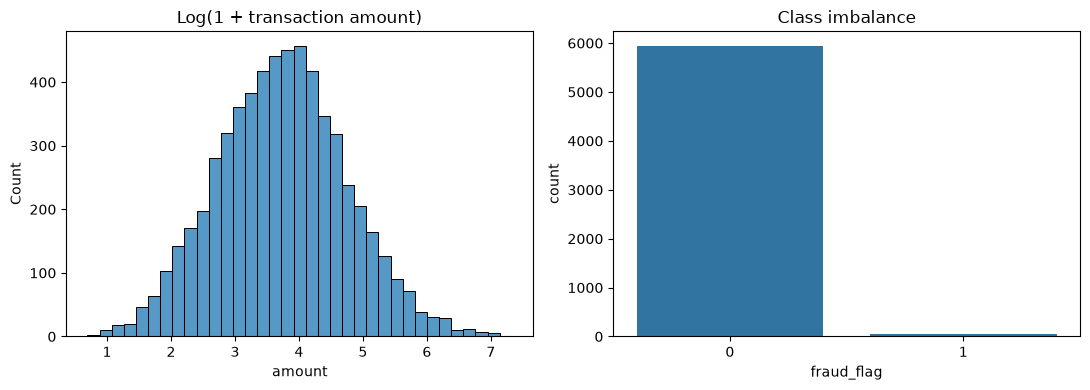

In [4]:
display(df[NUMERIC+['fraud_flag']].describe().T)
display(pd.DataFrame({'skewness':df[NUMERIC].skew(),'excess_kurtosis':df[NUMERIC].kurt()}))
fig,axes=plt.subplots(1,2,figsize=(11,4))
sns.histplot(np.log1p(df.amount),bins=35,ax=axes[0]);axes[0].set_title('Log(1 + transaction amount)')
sns.countplot(data=df,x='fraud_flag',ax=axes[1]);axes[1].set_title('Class imbalance')
plt.tight_layout();plt.show()

## 05 — Confidence interval for fraud prevalence
**Why:** a point estimate alone hides sampling uncertainty. Wilson interval is preferable to a simple normal approximation for proportions. This interval describes sampling variability in the synthetic population, not real bank fraud.

In [5]:
from scipy.stats import norm
n=len(df); p=df.fraud_flag.mean(); z=norm.ppf(.975)
den=1+z*z/n
center=(p+z*z/(2*n))/den
half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/den
print(f'Estimated fraud rate: {p:.2%}; 95% Wilson CI: [{center-half:.2%}, {center+half:.2%}]')

Estimated fraud rate: 0.95%; 95% Wilson CI: [0.73%, 1.23%]


## 06 — Hypothesis tests and effect sizes
**Why:** tests assess evidence of association, not causality. Mann–Whitney U compares amount distributions robustly; chi-square tests categorical association; point-biserial correlation measures linear association with binary fraud. Multiple exploratory tests can inflate false discoveries.

In [6]:
legit=df.loc[df.fraud_flag==0,'amount']; fraud=df.loc[df.fraud_flag==1,'amount']
u,p_mw=stats.mannwhitneyu(fraud,legit,alternative='two-sided')
ct=pd.crosstab(df.new_device,df.fraud_flag)
chi2,p_chi,dof,expected=stats.chi2_contingency(ct)
r,p_corr=stats.pointbiserialr(df.fraud_flag,df.amount)
print(f'Mann-Whitney amount: U={u:.0f}, p={p_mw:.5g}')
print(f'Chi-square new device vs fraud: chi2={chi2:.2f}, p={p_chi:.5g}')
print(f'Point-biserial amount vs fraud: r={r:.3f}, p={p_corr:.5g}')
print('Cramer V:',round(np.sqrt(chi2/(len(df)*min(ct.shape[0]-1,ct.shape[1]-1))),3))
display(ct)

Mann-Whitney amount: U=160542, p=0.49738
Chi-square new device vs fraud: chi2=7.32, p=0.0068244
Point-biserial amount vs fraud: r=0.003, p=0.793
Cramer V: 0.035


fraud_flag,0,1
new_device,,
0,4927,39
1,1016,18


## 07 — Correlation, group summaries, and visualization
**Why:** correlation detects redundancy and association, but not causation. Examine group fraud rates without treating exploratory findings as proof.

,sessions,fraud_rate,mean_amount
merchant_category,,,
electronics,1187,0.017692,66.026832
fuel,1248,0.008814,72.263622
travel,1185,0.007595,70.285316
online,1189,0.007569,71.488436
grocery,1191,0.005877,68.921906


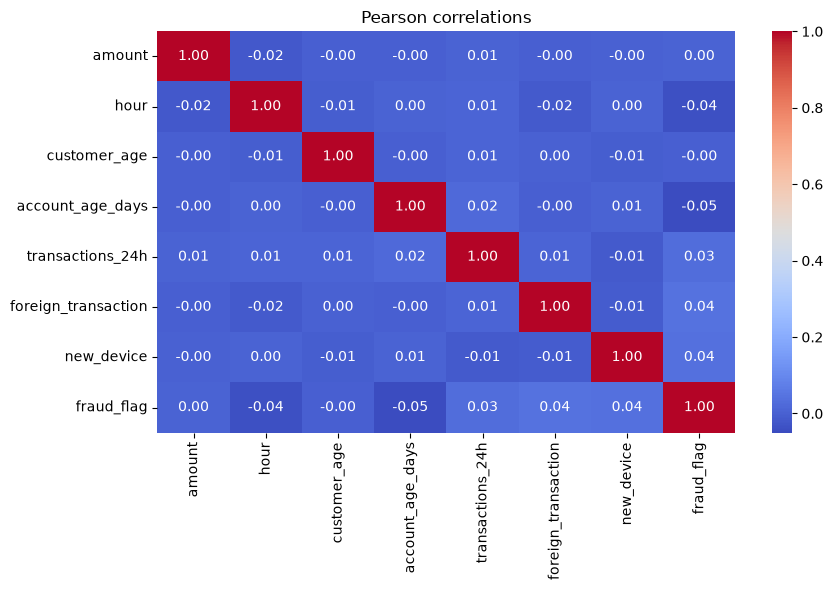

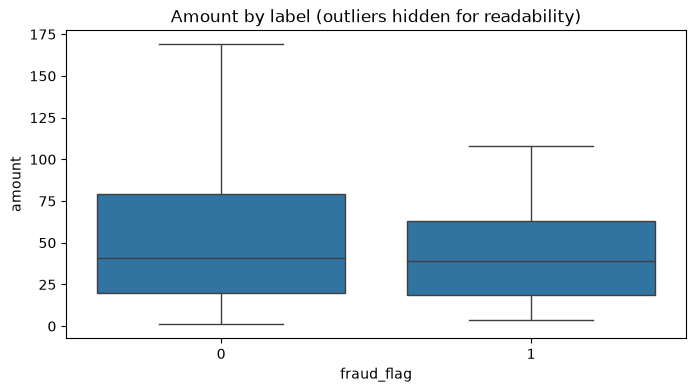

In [7]:
display(df.groupby('merchant_category').agg(sessions=('fraud_flag','size'),fraud_rate=('fraud_flag','mean'),mean_amount=('amount','mean')).sort_values('fraud_rate',ascending=False))
plt.figure(figsize=(9,6));sns.heatmap(df[NUMERIC+['fraud_flag']].corr(),annot=True,fmt='.2f',cmap='coolwarm');plt.title('Pearson correlations');plt.tight_layout();plt.show()
plt.figure(figsize=(8,4));sns.boxplot(data=df,x='fraud_flag',y='amount',showfliers=False);plt.title('Amount by label (outliers hidden for readability)');plt.show()

## 08 — Train/validation/test design and leakage prevention
**Why:** hold out a test set before tuning. Stratification preserves rare fraud rates. Preprocessing is fit only inside the training folds. In production use chronological and entity-aware splits when transactions share customers or time dependencies.

In [8]:
X=df[FEATURES].copy();y=df.fraud_flag.astype(int)
X_dev,X_test,y_dev,y_test=train_test_split(X,y,test_size=.20,stratify=y,random_state=SEED)
X_train,X_val,y_train,y_val=train_test_split(X_dev,y_dev,test_size=.25,stratify=y_dev,random_state=SEED)
print('Train/val/test:',len(X_train),len(X_val),len(X_test))
print('Rates:',*[round(v.mean(),4) for v in [y_train,y_val,y_test]])

Train/val/test: 3600 1200 1200
Rates: 0.0097 0.0092 0.0092


## 09 — Baseline: always predict legitimate
**Why:** accuracy can look excellent even when no fraud is found. Always compare against a simple baseline.

In [9]:
baseline=np.zeros(len(y_val),dtype=int)
print('Baseline accuracy:',accuracy_score(y_val,baseline))
print('Baseline fraud recall:',recall_score(y_val,baseline,zero_division=0))
print('Baseline F1:',f1_score(y_val,baseline,zero_division=0))

Baseline accuracy: 0.9908333333333333
Baseline fraud recall: 0.0
Baseline F1: 0.0


## 10 — Train and compare nine machine learning classifiers
**Why each:** Logistic Regression is interpretable; Naive Bayes is fast; KNN is distance-based; Decision Tree provides rules; Random Forest and Extra Trees reduce tree variance; Gradient Boosting and Histogram Gradient Boosting learn nonlinearities; SVM learns nonlinear decision boundaries. Scaling and encoding happen inside each pipeline.

**Metrics:** PR-AUC (average precision) is especially useful with rare fraud; ROC-AUC measures ranking; recall catches fraud; precision controls false alerts; F1 balances precision and recall. This training stage may take a few minutes.

In [10]:
models=candidate_models(); fitted={}; rows=[]
for name,estimator in models.items():
    pipe=make_pipeline(estimator)
    pipe.fit(X_train,y_train)
    prob=pipe.predict_proba(X_val)[:,1]
    pred=(prob>=.5).astype(int)
    rows.append({'model':name,'accuracy':accuracy_score(y_val,pred),
        'precision':precision_score(y_val,pred,zero_division=0),
        'recall':recall_score(y_val,pred,zero_division=0),
        'f1':f1_score(y_val,pred,zero_division=0),
        'roc_auc':roc_auc_score(y_val,prob),'pr_auc':average_precision_score(y_val,prob)})
    fitted[name]=pipe
results=pd.DataFrame(rows).sort_values('pr_auc',ascending=False).reset_index(drop=True)
display(results.round(4))
results.to_csv(ROOT/'reports/model_comparison.csv',index=False)

C:\Users\Dr.Yash\anaconda3\envs\Banking-Fraud\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,model,accuracy,precision,recall,f1,roc_auc,pr_auc
0,Gaussian Naive Bayes,0.9808,0.0714,0.0909,0.0800,0.7227,0.0279
1,Logistic Regression,0.7017,0.0247,0.8182,0.0479,0.7801,0.0264
2,Gradient Boosting,0.9833,0.0000,0.0000,0.0000,0.6446,0.0143
3,Histogram Gradient Boosting,0.9900,0.0000,0.0000,0.0000,0.6222,0.0140
4,Extra Trees,0.9858,0.0000,0.0000,0.0000,0.6051,0.0136
5,Random Forest,0.9875,0.0000,0.0000,0.0000,0.5698,0.0113
6,SVM,0.9908,0.0000,0.0000,0.0000,0.4978,0.0101
7,KNN,0.9908,0.0000,0.0000,0.0000,0.5253,0.0098
8,Decision Tree,0.8108,0.0091,0.1818,0.0173,0.4424,0.0088


## 11 — Stratified cross-validation on development data
**Why:** a single split is noisy. Cross-validation estimates variation while preserving class proportions. Here we cross-validate the top 3 validation models; the untouched test set remains sealed.

In [11]:
cv=StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED)
cv_rows=[]
for name in results.model.head(3):
    scores=cross_validate(make_pipeline(clone(models[name])),X_dev,y_dev,cv=cv,
                          scoring={'ap':'average_precision','roc':'roc_auc','recall':'recall'},n_jobs=1)
    cv_rows.append({'model':name,'cv_pr_auc_mean':scores['test_ap'].mean(),
                    'cv_pr_auc_std':scores['test_ap'].std(),'cv_recall_mean':scores['test_recall'].mean()})
display(pd.DataFrame(cv_rows).round(4))

,model,cv_pr_auc_mean,cv_pr_auc_std,cv_recall_mean
0,Gaussian Naive Bayes,0.0147,0.0020,0.0000
1,Logistic Regression,0.0232,0.0078,0.5208
2,Gradient Boosting,0.0232,0.0046,0.0208


## 12 — Hyperparameter tuning (optional, moderate compute)
**Why:** tune complexity using development folds, not the final test set. Randomized search explores a compact Random Forest search space. Set `RUN_TUNING=False` for the fastest first run.

In [12]:
RUN_TUNING=False
if RUN_TUNING:
    from sklearn.ensemble import RandomForestClassifier
    search=RandomizedSearchCV(make_pipeline(RandomForestClassifier(random_state=SEED,n_jobs=-1,class_weight='balanced')),
        param_distributions={'model__n_estimators':[80,120,180],
            'model__max_depth':[4,8,None],'model__min_samples_leaf':[1,3,8]},
        n_iter=6,cv=cv,scoring='average_precision',random_state=SEED,n_jobs=1,refit=True)
    search.fit(X_train,y_train)
    threshold_model=search.best_estimator_
    print('Tuned PR-AUC:',search.best_score_,'Parameters:',search.best_params_)
else:
    best_name=results.iloc[0]['model']
    threshold_model=fitted[best_name]
    print('Selected by validation PR-AUC:',best_name)

Selected by validation PR-AUC: Gaussian Naive Bayes


## 13 — Select an alert threshold on validation data
**Why:** 0.5 is rarely optimal for fraud. Choose threshold based on validation precision/recall and business alert capacity; never choose it using test labels.

Threshold selection uses a model trained on training-only data; only afterwards is the final model refit on all development data.

In [13]:
val_probs=threshold_model.predict_proba(X_val)[:,1]
precision,recall,thresholds=precision_recall_curve(y_val,val_probs)
f1_scores=2*precision[:-1]*recall[:-1]/np.maximum(precision[:-1]+recall[:-1],1e-12)
chosen_threshold=float(thresholds[np.argmax(f1_scores)])
print('Validation F1-optimal threshold:',round(chosen_threshold,4))
print('For production, replace F1 optimization with expected cost / review-capacity constraints.')
# Refit on all development data AFTER threshold selection.
best_model=clone(threshold_model).fit(X_dev,y_dev)

Validation F1-optimal threshold: 0.9526
For production, replace F1 optimization with expected cost / review-capacity constraints.


## 14 — Final holdout evaluation (run once)
**Why:** test metrics approximate performance on unseen data when the holdout reflects deployment. Since model choice and threshold were selected on development data, do not retune after viewing test results.

              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1189
           1       0.00      0.00      0.00        11

    accuracy                           0.98      1200
   macro avg       0.50      0.50      0.50      1200
weighted avg       0.98      0.98      0.98      1200

Test ROC-AUC: 0.7021
Test PR-AUC: 0.0237


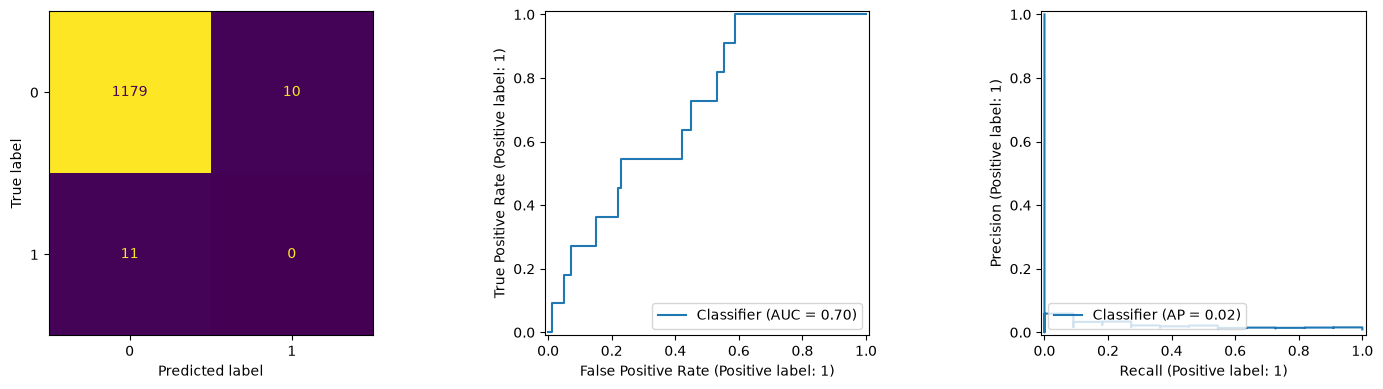

In [14]:
test_probs=best_model.predict_proba(X_test)[:,1]
test_pred=(test_probs>=chosen_threshold).astype(int)
print(classification_report(y_test,test_pred,zero_division=0))
print('Test ROC-AUC:',round(roc_auc_score(y_test,test_probs),4))
print('Test PR-AUC:',round(average_precision_score(y_test,test_probs),4))
fig,axs=plt.subplots(1,3,figsize=(15,4))
ConfusionMatrixDisplay.from_predictions(y_test,test_pred,ax=axs[0],colorbar=False)
RocCurveDisplay.from_predictions(y_test,test_probs,ax=axs[1])
PrecisionRecallDisplay.from_predictions(y_test,test_probs,ax=axs[2])
plt.tight_layout();plt.savefig(ROOT/'reports/figures/evaluation.png',dpi=140);plt.show()

## 15 — Model explainability: permutation importance
**Why:** assess how much shuffling a feature harms held-out PR-AUC. This is model-agnostic and measures predictive dependence, not causation. Correlated predictors can share importance.

,mean_pr_auc_drop
foreign_transaction,0.005976
new_device,0.005749
merchant_category,0.003749
account_age_days,0.000898
transactions_24h,0.000489
hour,0.000286
customer_age,-0.001038
amount,-0.001446
region,-0.009208


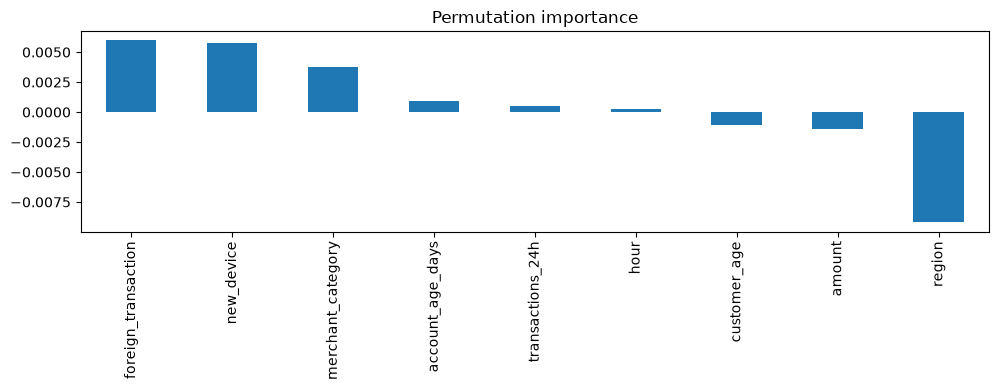

In [15]:
importance=permutation_importance(best_model,X_test,y_test,n_repeats=3,
    random_state=SEED,scoring='average_precision',n_jobs=1)
imp=pd.Series(importance.importances_mean,index=FEATURES).sort_values(ascending=False)
display(imp.to_frame('mean_pr_auc_drop'))
imp.plot.bar(figsize=(10,4),title='Permutation importance');plt.tight_layout();plt.show()

## 16 — Save and reload model, metadata and predictions
**Why:** reproducible deployment requires a serialized preprocessing+model pipeline, schema and decision threshold. Only load joblib files you trust.

In [16]:
model_path=ROOT/'models/fraud_pipeline.joblib'
joblib.dump(best_model,model_path)
metadata={'features':FEATURES,'threshold':chosen_threshold,'seed':SEED,
          'fraud_rate':float(y.mean()),'model':('tuned Random Forest' if RUN_TUNING else best_name)}
(ROOT/'models/metadata.json').write_text(json.dumps(metadata,indent=2))
loaded=joblib.load(model_path)
example=X_test.iloc[[0]].copy()
score=float(loaded.predict_proba(example)[0,1])
print('Example fraud probability:',round(score,4),'Alert:',score>=chosen_threshold)
print('Saved:',model_path)

Example fraud probability: 0.0011 Alert: False
Saved: c:\Data Science\banking_fraud_detection\models\fraud_pipeline.joblib


## 17 — Monitoring and production considerations
**Why:** deployment is not the end. Monitor alert volume, precision with delayed confirmed labels, drift, subgroup fairness, inference latency, calibration, false positives, privacy, access controls, and retraining triggers. Real bank data needs governance and human review.

**Next extensions:** time-based validation; customer-aware splits; calibration curves; class weighting vs resampling (inside CV only); cost-sensitive thresholds; drift dashboards; MLflow; FastAPI; CI/CD; approval workflow. Statistical tests and algorithms in this notebook are broad educational coverage, not literally every statistical method or ML algorithm.